# AI651 – Assignment 2, Question 2: *Motion or Memory?*
Complete experiment code (ConvLSTM on Moving MNIST). Run top to bottom on a Colab GPU (T4 is fine).

## Section map and what the report needs **before** you run each part

| Section | Contents | Report items produced | Write **before** running? |
|---|---|---|---|
| 0 | Setup, repo/git helpers | – | – |
| 1 | Data, transforms, windows, **Table 1** | Table 1 | – |
| 2 | Optical flow, **Figure 1** | Figure 1, Q2.1, Q2.2 | – |
| 3 | Model A, reach helper, training, **Table 2**, **Figure 2** | Table 2, Fig 2, Q2.3, Q2.4 | **Q2.3** (derive reach by hand first; the helper only checks it) |
| **GATE 1** | | | **Write and commit Q2.5** (needs Q2.1–Q2.3). Do not run Section 4 before. |
| 4 | Testing the baseline: **Tables 3, 4**, **Figures 3, 4, 5** | Q2.6–Q2.10 | Q2.5 (committed) |
| **GATE 2** | | | **Write and commit Q2.11.** Do not run anything in Section 5 before. |
| 5 | Models B, C, D (candidate selection on validation only), **Table 5** | Q2.12–Q2.14 | Q2.11 (committed) |
| 6 | Symmetrised forecasters, **Table 6**, **Figure 6** | Q2.15–Q2.17 | – |
| 7 | Save everything | – | – |

Notes
* Total cost: 8 trainings × 30 epochs (A, B, C, D × seeds 0,1), +2 if you also train D+B. Checkpoints are saved, so a disconnect does not lose finished runs.
* Set `QUICK_TEST = True` in Section 0 only to debug the pipeline. Set it back to `False` for every number you report.
* The test split is used only for evaluation/analysis. Model-D candidates are compared on **validation** only.
* Answers to Q2.1–Q2.17 are prose and go in your report; this notebook produces the tables, figures and numbers they refer to.

# Section 0 – Setup

In [1]:
!pip -q install opencv-python-headless imageio pandas
import os, time, json, math, shutil, subprocess
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import torchvision, cv2, imageio, pandas as pd
import matplotlib.pyplot as plt

device = 'cuda' if torch.cuda.is_available() else 'cpu'
HARDWARE = torch.cuda.get_device_name(0) if device == 'cuda' else 'CPU'
print('torch', torch.__version__, '| device:', device, '|', HARDWARE)   # report the hardware

QUICK_TEST = False          # True only for debugging (2 epochs); False for all reported numbers
EPOCHS = 2 if QUICK_TEST else 30
SEEDS = (0, 1)
for d in ['ckpt', 'figures', 'gifs', 'tables', 'answers']:
    os.makedirs(d, exist_ok=True)

# Optional: keep checkpoints on Drive so they survive runtime resets
# from google.colab import drive; drive.mount('/content/drive')
# os.makedirs('/content/drive/MyDrive/ai651_pa2_ckpt', exist_ok=True); shutil.rmtree('ckpt'); os.symlink('/content/drive/MyDrive/ai651_pa2_ckpt','ckpt')

torch 2.11.0+cu130 | device: cuda | Tesla T4


In [2]:
# ---- Git helpers: the handout requires Q2.5 and Q2.11 to be COMMITTED before the experiments.
# Set REPO_URL (https://<token>@github.com/<user>/<repo>.git) or run `git init` yourself in the working dir.
REPO_URL = 'https://github.com/ramsha4rasheed-png/DLSTGL_PA2'
def git(*a):
    r = subprocess.run(['git', *a], capture_output=True, text=True); print((r.stdout + r.stderr).strip())
if REPO_URL and not os.path.exists('.git'):
    git('init'); git('remote', 'add', 'origin', REPO_URL)
elif not os.path.exists('.git'):
    git('init')

def commit_answer(name, text, push=False):
    assert 'PASTE' not in text, 'Replace the placeholder with your written answer first.'
    path = f'answers/{name}.md'
    open(path, 'w').write(text)
    git('add', path); git('commit', '-m', f'Add {name} (written before experiments)')
    if push: git('push', '-u', 'origin', 'HEAD')

Initialized empty Git repository in /content/.git/
hint: Using 'master' as the name for the initial branch. This default branch name
hint: is subject to change. To configure the initial branch name to use in all
hint: of your new repositories, which will suppress this warning, call:
hint: 
hint: 	git config --global init.defaultBranch <name>
hint: 
hint: Names commonly chosen instead of 'master' are 'main', 'trunk' and
hint: 'development'. The just-created branch can be renamed via this command:
hint: 
hint: 	git branch -m <name>



# Section 1 – Data, transformations, windows, Table 1
Manual split by video index: 0–7999 train, 8000–8999 validation, 9000–9999 test. Frames are numbered 1–20 in the handout (0-indexed in code).

In [3]:
ds = torchvision.datasets.MovingMNIST(root='data', split=None, download=True)
def _get(i):
    v = ds[i]; return v[0] if isinstance(v, (tuple, list)) else v
VID = torch.stack([_get(i) for i in range(len(ds))])
if VID.ndim == 4: VID = VID.unsqueeze(2)
if VID.dtype != torch.uint8: VID = VID.round().clamp(0, 255).to(torch.uint8)
assert VID.shape == (10000, 20, 1, 64, 64) and VID.max() > 1, VID.shape

TRAIN_U8, VAL_U8, TEST_U8 = VID[:8000], VID[8000:9000], VID[9000:]   # uint8 on CPU
TRAIN_DEV = TRAIN_U8.to(device)                                       # uint8 on device (training sampler)
VAL  = VAL_U8.float() / 255
TEST = TEST_U8.float() / 255
print(TRAIN_U8.shape, VAL.shape, TEST.shape, TEST.min().item(), TEST.max().item())

100%|██████████| 819M/819M [00:27<00:00, 29.5MB/s]


torch.Size([8000, 20, 1, 64, 64]) torch.Size([1000, 20, 1, 64, 64]) torch.Size([1000, 20, 1, 64, 64]) 0.0 1.0


In [4]:
# ---- Symmetries.  All act on the last two dims, so they work on frames, clips and batches.
def M(x): return torch.flip(x, dims=(-1,))                    # (Mx)[i,j] = x[i,63-j]
def R(x, k=1): return torch.rot90(x, k=k, dims=(-2, -1))      # 90 deg anticlockwise, k times
G = [(m, a) for m in (0, 1) for a in range(4)]                # g=(m,a) -> M^m R^a (rotate first, then mirror)
def apply_g(x, g):
    m, a = g
    y = R(x, a)
    return M(y) if m else y
def inv_g(x, g):
    m, a = g
    y = M(x) if m else x
    return R(y, -a)
Rot = lambda x: R(x, 1)

# ---- Windows (t is 1-indexed as in the handout)
def window_idx(t, k):
    xi = [t - 1 + i * k for i in range(5)]
    yi = [t - 1 + (5 + i) * k for i in range(5)]
    yi = [j for j in yi if j <= 19]                  # keep only target frames that exist (frame <= 20)
    assert xi[-1] <= 19 and len(yi) >= 1
    return xi, yi
def window(v, t, k):
    xi, yi = window_idx(t, k); return v[xi], v[yi]
def valid_starts(k, min_targets):                   # min_targets=5: models A,B ; 2: speed-augmented models C,D
    return [t for t in range(1, 21) if t - 1 + (4 + min_targets) * k <= 19]
def eval_set(V, k, t=1):
    xi, yi = window_idx(t, k); return V[:, xi], V[:, yi]

print({k: valid_starts(k, 5) for k in (1, 2, 3)})
print({k: valid_starts(k, 2) for k in (1, 2, 3)})   # expected 1..14, 1..8, 1..2
for g in G:                                          # inverse sanity check on all 8 symmetries
    z = torch.rand(3, 1, 64, 64); assert torch.equal(inv_g(apply_g(z, g), g), z)

{1: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 2: [1, 2], 3: []}
{1: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14], 2: [1, 2, 3, 4, 5, 6, 7, 8], 3: [1, 2]}


In [5]:
# ---- TABLE 1: correctness checks
torch.manual_seed(0); xr = torch.rand(20, 1, 64, 64)
p = torch.zeros(20, 1, 64, 64); p[7, 0, 10, 20] = 1
md_ = lambda a, b: (a - b).abs().max().item()
def bright(v):
    nz = torch.nonzero(v)[0]; return (int(nz[0]), int(nz[2]), int(nz[3]))
fv = torch.arange(1, 21).float().view(20, 1, 1, 1).expand(20, 1, 64, 64)    # frame f filled with value f
def frames(k):
    xi, yi = window_idx(1, k)
    return [int(fv[i, 0, 0, 0]) for i in xi], [int(fv[j, 0, 0, 0]) for j in yi]
rows = [
 ('(a) max|M(M(x)) - x|', '0', f'{md_(M(M(xr)), xr)}  equal={torch.equal(M(M(xr)), xr)}'),
 ('(b) max|R^4(x) - x|', '0', f'{md_(R(xr, 4), xr)}  equal={torch.equal(R(xr, 4), xr)}'),
 ('(c) max|M R M(x) - R^-1(x)|', '0', f'{md_(M(R(M(xr))), R(xr, -1))}  equal={torch.equal(M(R(M(xr))), R(xr, -1))}'),
 ('(d) bright pixel of M(p)', '(7, 10, 43)', str(bright(M(p)))),
 ('(e) bright pixel of R(p)', '(7, 43, 10)', str(bright(R(p)))),
 ('(f) 1x input / target', '1-5 / 6-10', str(frames(1))),
 ('(g) 2x input / target', '1,3,5,7,9 / 11,13,15,17,19', str(frames(2))),
 ('(h) 3x input / target', '1,4,7,10,13 / 16,19', str(frames(3))),
]
T1 = pd.DataFrame(rows, columns=['Check', 'Expected', 'Yours']); T1.to_csv('tables/table1.csv', index=False)
pd.set_option('display.max_colwidth', 200, 'display.width', 250); display(T1)

,Check,Expected,Yours
0,(a) max|M(M(x)) - x|,0,0.0 equal=True
1,(b) max|R^4(x) - x|,0,0.0 equal=True
2,(c) max|M R M(x) - R^-1(x)|,0,0.0 equal=True
3,(d) bright pixel of M(p),"(7, 10, 43)","(7, 10, 43)"
4,(e) bright pixel of R(p),"(7, 43, 10)","(7, 43, 10)"
5,(f) 1x input / target,1-5 / 6-10,"([1, 2, 3, 4, 5], [6, 7, 8, 9, 10])"
6,(g) 2x input / target,"1,3,5,7,9 / 11,13,15,17,19","([1, 3, 5, 7, 9], [11, 13, 15, 17, 19])"
7,(h) 3x input / target,"1,4,7,10,13 / 16,19","([1, 4, 7, 10, 13], [16, 19])"


# Section 2 – Is the training data already symmetric? (Figure 1)
Farneback flow, exact settings from the handout, first 50 training videos, 950 frame pairs.

**Report after running:** Figure 1 (caption: median speed and number of kept pixels), **Q2.1**, **Q2.2**.

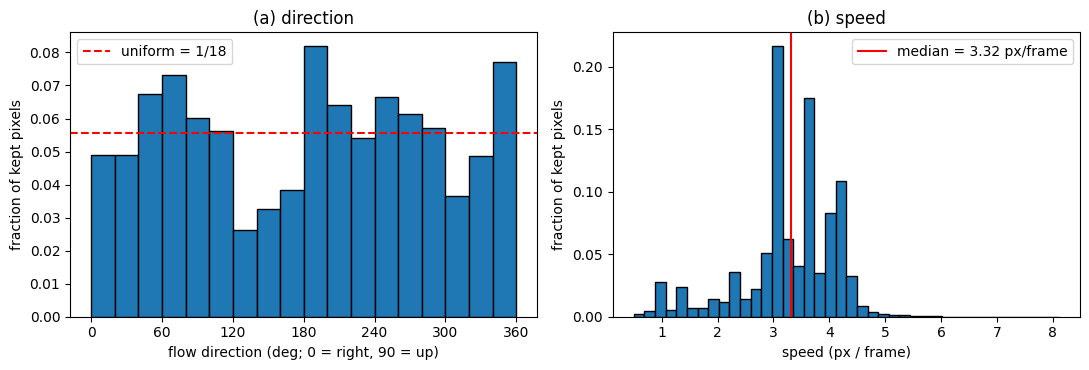

CAPTION: median speed = 3.32 px/frame, kept pixels = 103050
TV(h, mirrored)  = 0.1321203299369238
TV(h, rotated90) = 0.19998059194565748
TV(h, uniform)   = 0.10985929160601651
2x / 3x typical speed (px/frame) ~ 6.635005 9.952507


In [6]:
def flow_stats(V_u8, n_videos=50):
    th, sp = [], []
    for v in range(n_videos):
        fr = np.ascontiguousarray(V_u8[v, :, 0].numpy())          # (20,64,64) uint8 == (x/255)*255
        for s in range(19):                                        # pairs (x_s, x_{s+1}), s=1..19
            prev, nxt = fr[s], fr[s + 1]
            flow = cv2.calcOpticalFlowFarneback(prev, nxt, None, 0.5, 3, 15, 3, 5, 1.2, 0)
            dx, dy = flow[..., 0], flow[..., 1]
            mag = np.sqrt(dx ** 2 + dy ** 2)
            keep = (prev / 255.0 > 0.2) & (nxt / 255.0 > 0.2) & (mag > 0.5)
            th.append(np.degrees(np.arctan2(-dy[keep], dx[keep])) % 360); sp.append(mag[keep])
    return np.concatenate(th), np.concatenate(sp)
theta, speed = flow_stats(TRAIN_U8)
med = np.median(speed); NKEPT = len(theta)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
cnt, edges = np.histogram(theta, bins=18, range=(0, 360))
ax[0].bar(edges[:-1], cnt / NKEPT, width=20, align='edge', edgecolor='k')
ax[0].axhline(1 / 18, color='r', ls='--', label='uniform = 1/18'); ax[0].set_xticks(range(0, 361, 60))
ax[0].set_xlabel('flow direction (deg; 0 = right, 90 = up)'); ax[0].set_ylabel('fraction of kept pixels'); ax[0].legend(); ax[0].set_title('(a) direction')
ax[1].hist(speed, bins=40, weights=np.ones_like(speed) / NKEPT, edgecolor='k')
ax[1].axvline(med, color='r', label=f'median = {med:.3g} px/frame'); ax[1].set_xlabel('speed (px / frame)'); ax[1].set_ylabel('fraction of kept pixels'); ax[1].legend(); ax[1].set_title('(b) speed')
plt.tight_layout(); plt.savefig('figures/fig1.png', dpi=150); plt.show()
print(f'CAPTION: median speed = {med:.3g} px/frame, kept pixels = {NKEPT}')

# helper diagnostics for Q2.1: how far is the direction histogram from its mirrored / 90-deg-rotated version?
def hist18(t): return np.histogram(t, bins=18, range=(0, 360))[0] / len(t)
h0 = hist18(theta)
print('TV(h, mirrored)  =', 0.5 * np.abs(h0 - hist18((180 - theta) % 360)).sum())
print('TV(h, rotated90) =', 0.5 * np.abs(h0 - hist18((theta + 90) % 360)).sum())
print('TV(h, uniform)   =', 0.5 * np.abs(h0 - 1 / 18).sum())
print('2x / 3x typical speed (px/frame) ~', 2 * med, 3 * med)

# Section 3 – Baseline ConvLSTM (model A), reach, Table 2, Figure 2

### REPORT BEFORE RUNNING THE REACH CELL: **Q2.3**
Derive model A's one-step reach **by hand** (patch size, kernels, layers, recurrence, handout conventions) and write it down first. The helper below only *checks* your arithmetic (and is reused for model D in Q2.12).

In [7]:
class ConvLSTMCell(nn.Module):
    def __init__(self, cin, ch, k=3, dil=1):
        super().__init__()
        self.ch = ch
        self.conv = nn.Conv2d(cin + ch, 4 * ch, k, stride=1, padding=dil * (k // 2), dilation=dil, bias=True)
    def forward(self, u, state):
        h, c = state
        i, f, o, g = torch.chunk(self.conv(torch.cat([u, h], 1)), 4, 1)
        c = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)
        h = torch.sigmoid(o) * torch.tanh(c)
        return h, c

class ConvRNN(nn.Module):
    # patch=4, hid=64, ks=(3,3), dil=(1,1)  ==  model A.  Other values give model-D variants.
    def __init__(self, patch=4, hid=64, ks=(3, 3), dil=(1, 1)):
        super().__init__()
        self.patch, self.hid = patch, hid
        pc = patch * patch
        cin = [pc] + [hid] * (len(ks) - 1)
        self.cells = nn.ModuleList([ConvLSTMCell(cin[l], hid, ks[l], dil[l]) for l in range(len(ks))])
        self.out = nn.Conv2d(hid, pc, 1)
    def forward(self, X):                       # X: (B,5,1,64,64) -> (B,5,1,64,64)
        B = X.shape[0]; g = 64 // self.patch
        st = [(X.new_zeros(B, self.hid, g, g), X.new_zeros(B, self.hid, g, g)) for _ in self.cells]
        outs, pred = [], None
        for tau in range(1, 10):                # 9 steps, no teacher forcing
            frame = X[:, tau - 1] if tau <= 5 else pred
            u = F.pixel_unshuffle(frame, self.patch)
            for l, cell in enumerate(self.cells):
                st[l] = cell(u, st[l]); u = st[l][0]
            pred = torch.sigmoid(F.pixel_shuffle(self.out(u), self.patch))    # = x_hat_{tau+1}
            if tau >= 5: outs.append(pred)      # steps 5..9 -> Y_hat; steps 1..4 discarded
        return torch.stack(outs, 1)

def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)
CFG_A = dict(patch=4, hid=64, ks=(3, 3), dil=(1, 1))
assert n_params(ConvRNN(**CFG_A)) == 480784, n_params(ConvRNN(**CFG_A))
print('model A parameters:', n_params(ConvRNN(**CFG_A)), '(handout: 480,784)')
PARAM_LIMIT_D = int(1.5 * 480784)    # 721,176

model A parameters: 480784 (handout: 480,784)


In [8]:
# Reach helper (CHECK ONLY - do your own derivation for Q2.3 / Q2.12).
# Radius of layer l in folded cells = dil*(k-1)/2; one folded cell = `patch` original pixels.
# Paths within one step: new input / h^(1)_{t-1} traverse all conv layers; h^(l)_{t-1} traverses layers l..L; 1x1 conv, (un)shuffle and c-states add nothing.
def reach_px(patch, ks, dil):
    r = [d * (k - 1) // 2 for k, d in zip(ks, dil)]
    return patch * max(sum(r[l:]) for l in range(len(r)))
print('reach of A (px / step):', reach_px(**{k: v for k, v in CFG_A.items() if k != 'hid'}))

reach of A (px / step): 8


### Training / evaluation machinery (same protocol for every learned model)
Adam, lr 1e-3, no schedule, batch 32, 30 epochs, final weights, one random window per training video per epoch, per-video-equal-weight masked MSE, no teacher forcing, no gradient clipping. Seed controls init, shuffling, window and augmentation sampling.

In [9]:
def sample_batch(U8, idx, rng, speed_aug, sym_aug):
    Xs, Ys, Ms = [], [], []
    for i in idx:
        k = int(rng.integers(1, 4)) if speed_aug else 1                 # k ~ U{1,2,3}
        t = int(rng.choice(valid_starts(k, 2 if speed_aug else 5)))      # t ~ U(allowed starts)
        x, y = window(U8[i], t, k)
        nT = y.shape[0]
        mask = torch.zeros(5, device=U8.device); mask[:nT] = 1
        if nT < 5: y = torch.cat([y, torch.zeros(5 - nT, *y.shape[1:], dtype=y.dtype, device=y.device)])
        if sym_aug:
            g = G[int(rng.integers(8))]; x, y = apply_g(x, g), apply_g(y, g)   # same g for input and target
        Xs.append(x); Ys.append(y); Ms.append(mask)
    return torch.stack(Xs).float() / 255, torch.stack(Ys).float() / 255, torch.stack(Ms)

def masked_loss(pred, Y, mask):
    se = ((pred - Y) ** 2).mean(dim=(2, 3, 4))                          # (B,5): mean over pixels, per frame
    return ((se * mask).sum(1) / mask.sum(1)).mean()                    # mean over available frames, then over videos

# ---- evaluation helpers
@torch.no_grad()
def run(f, X, bs=32):
    return torch.cat([f(X[b:b + bs].to(device)).cpu() for b in range(0, len(X), bs)])
def hmse(P, Y): return ((P[:, :Y.shape[1]] - Y) ** 2).mean(dim=(2, 3, 4))      # (N, nT) per-video per-horizon MSE
def perC(P_T, T_P): return ((P_T - T_P) ** 2).mean(dim=(2, 3, 4)).mean(1)       # per-video consistency gap (N,)

TS = {k: eval_set(TEST, k) for k in (1, 2, 3)}      # test windows (t=1) at 1x,2x,3x
VS = {k: eval_set(VAL, k) for k in (1, 2, 3)}       # validation windows

def metrics(f):
    o = {}
    X1, Y1 = TS[1]; P1 = run(f, X1); h = hmse(P1, Y1)
    o['MSEh'] = h.mean(0).tolist(); o['E5'] = h.mean().item(); o['E2_1x'] = h[:, :2].mean().item()
    for name, T in (('M', M), ('R', Rot)):
        PT = run(f, T(X1))
        o['C' + name] = perC(PT, T(P1)).mean().item()
        o['E' + name] = hmse(PT, T(Y1)).mean().item()
    X2, Y2 = TS[2]; h2 = hmse(run(f, X2), Y2); o['E2_2x'] = h2[:, :2].mean().item(); o['E5_2x'] = h2.mean().item()
    X3, Y3 = TS[3]; h3 = hmse(run(f, X3), Y3); o['E2_3x'] = h3[:, :2].mean().item()   # only 2 targets exist at 3x
    return o

def val_score(f):                                    # validation-only criterion for choosing model D
    s = {}
    for k in (1, 2, 3):
        X, Y = VS[k]; s[k] = hmse(run(f, X), Y)[:, :2].mean().item()
    return s

def time_inference(f, X, bs=32):
    # wall-clock for 1000 (1x,t=1) test videos at batch 32, eval/no_grad, timed after each batch is on device
    f(X[:bs].to(device))                             # one untimed warm-up (cuda init / cudnn autotune)
    tot = 0.0
    with torch.no_grad():
        for b in range(0, len(X), bs):
            xb = X[b:b + bs].to(device)
            if device == 'cuda': torch.cuda.synchronize()
            t0 = time.perf_counter(); f(xb)
            if device == 'cuda': torch.cuda.synchronize()
            tot += time.perf_counter() - t0
    return tot

blank = lambda X: torch.zeros_like(X)
copy_last = lambda X: X[:, -1:].expand(-1, 5, -1, -1, -1).contiguous()

# ---- formatting: 3 significant figures; scientific notation below 1e-3; "mean (seed0, seed1)"
def fmt(v):
    if isinstance(v, (int, np.integer)): return f'{int(v):,}'
    if v == 0: return '0'
    return f'{v:.2e}' if abs(v) < 1e-3 else f'{v:.3g}'
def ms(vals): return fmt(float(np.mean(vals))) if len(vals) == 1 else f'{fmt(float(np.mean(vals)))} (' + ', '.join(fmt(float(v)) for v in vals) + ')'

In [10]:
RES, MODELS = {}, {}          # RES[tag][seed] = dict of metrics ; MODELS[(tag,seed)] = trained nn.Module

def train_model(tag, cfg, seed, speed_aug=False, sym_aug=False, epochs=None, force=False):
    epochs = epochs or EPOCHS
    torch.manual_seed(seed)
    model = ConvRNN(**cfg).to(device)
    path = f'ckpt/{tag}_seed{seed}_ep{epochs}.pt'
    if os.path.exists(path) and not force:
        ck = torch.load(path, map_location=device); model.load_state_dict(ck['state']); model.eval()
        print(f'[{tag} seed {seed}] loaded {path}'); return model, ck['epoch_time'], ck['log']
    rng = np.random.default_rng(seed)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    ep_times, log = [], []
    for ep in range(epochs):
        model.train(); perm = rng.permutation(len(TRAIN_DEV)); tot = 0.0
        if device == 'cuda': torch.cuda.synchronize()
        t0 = time.perf_counter()
        for b in range(0, len(perm), 32):
            X, Y, Mk = sample_batch(TRAIN_DEV, perm[b:b + 32], rng, speed_aug, sym_aug)
            loss = masked_loss(model(X), Y, Mk)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); tot += loss.item() * len(X)
        if device == 'cuda': torch.cuda.synchronize()
        ep_times.append(time.perf_counter() - t0)
        model.eval(); X, Y = VS[1]                       # validation monitoring (not counted in training time)
        v = hmse(run(model, X), Y).mean().item()
        log.append((ep + 1, tot / len(perm), v))
        print(f'[{tag} s{seed}] ep {ep + 1:2d}/{epochs} train {tot / len(perm):.5f} | val E5 {v:.5f} | {ep_times[-1]:.1f}s')
    model.eval()
    torch.save({'state': model.state_dict(), 'epoch_time': float(np.mean(ep_times)), 'log': log}, path)
    return model, float(np.mean(ep_times)), log

def register(tag, seed, model, train_time):
    MODELS[(tag, seed)] = model; model.eval()
    r = metrics(model); r['params'] = n_params(model); r['train_time'] = train_time
    r['infer_time'] = time_inference(model, TS[1][0]); RES.setdefault(tag, {})[seed] = r
    print(f'{tag} seed {seed}: E5={r["E5"]:.4g}  CM={r["CM"]:.4g} EM={r["EM"]:.4g} CR={r["CR"]:.4g} ER={r["ER"]:.4g}')

# ---- reference predictors (deterministic)
for tag, f in (('Blank', blank), ('Copy-last', copy_last)):
    RES[tag] = {0: dict(metrics(f), params=0, train_time=0.0, infer_time=time_inference(f, TS[1][0]))}
print({k: round(v[0]['E5'], 5) for k, v in RES.items()})

{'Blank': 0.04256, 'Copy-last': 0.06408}


In [11]:
# ---- Train model A, seeds 0 and 1 (baseline: 1x only, no symmetry augmentation)
for s in SEEDS:
    m, tt, _ = train_model('A', CFG_A, s)
    register('A', s, m, tt)

[A s0] ep  1/30 train 0.04610 | val E5 0.03932 | 13.6s
[A s0] ep  2/30 train 0.03969 | val E5 0.03861 | 11.3s
[A s0] ep  3/30 train 0.03868 | val E5 0.03744 | 11.4s
[A s0] ep  4/30 train 0.03712 | val E5 0.03554 | 11.6s
[A s0] ep  5/30 train 0.03527 | val E5 0.03374 | 11.8s
[A s0] ep  6/30 train 0.03360 | val E5 0.03258 | 12.1s
[A s0] ep  7/30 train 0.03227 | val E5 0.03132 | 12.5s
[A s0] ep  8/30 train 0.03123 | val E5 0.03030 | 12.3s
[A s0] ep  9/30 train 0.03047 | val E5 0.02971 | 12.0s
[A s0] ep 10/30 train 0.02981 | val E5 0.02929 | 11.8s
[A s0] ep 11/30 train 0.02942 | val E5 0.02913 | 11.8s
[A s0] ep 12/30 train 0.02890 | val E5 0.02830 | 12.0s
[A s0] ep 13/30 train 0.02845 | val E5 0.02817 | 12.1s
[A s0] ep 14/30 train 0.02808 | val E5 0.02758 | 12.2s
[A s0] ep 15/30 train 0.02770 | val E5 0.02717 | 12.1s
[A s0] ep 16/30 train 0.02730 | val E5 0.02758 | 12.0s
[A s0] ep 17/30 train 0.02689 | val E5 0.02680 | 12.0s
[A s0] ep 18/30 train 0.02649 | val E5 0.02667 | 12.0s
[A s0] ep 

In [12]:
# ---- TABLE 2
def table2():
    rows = []
    for tag in ('A', 'Blank', 'Copy-last'):
        seeds = sorted(RES[tag]); d = {'Model': tag}
        for h in range(5): d[f'MSE{h + 1}'] = ms([RES[tag][s]['MSEh'][h] for s in seeds])
        d['E(5)'] = ms([RES[tag][s]['E5'] for s in seeds]); d['Params'] = fmt(RES[tag][seeds[0]]['params'])
        rows.append(d)
    return pd.DataFrame(rows)
T2 = table2(); T2.to_csv('tables/table2.csv', index=False); display(T2)
print('hardware:', HARDWARE)

,Model,MSE1,MSE2,MSE3,MSE4,MSE5,E(5),Params
0,A,"0.0167 (0.0173, 0.016)","0.0202 (0.0207, 0.0196)","0.0225 (0.023, 0.022)","0.0242 (0.0247, 0.0238)","0.0259 (0.0263, 0.0255)","0.0219 (0.0224, 0.0214)","480,784"
1,Blank,0.0426,0.0426,0.0426,0.0425,0.0425,0.0426,0
2,Copy-last,0.0492,0.0604,0.0669,0.0708,0.0732,0.0641,0


hardware: Tesla T4


Figure 2 test-video indices (0..999 within test split): [851, 313, 12]


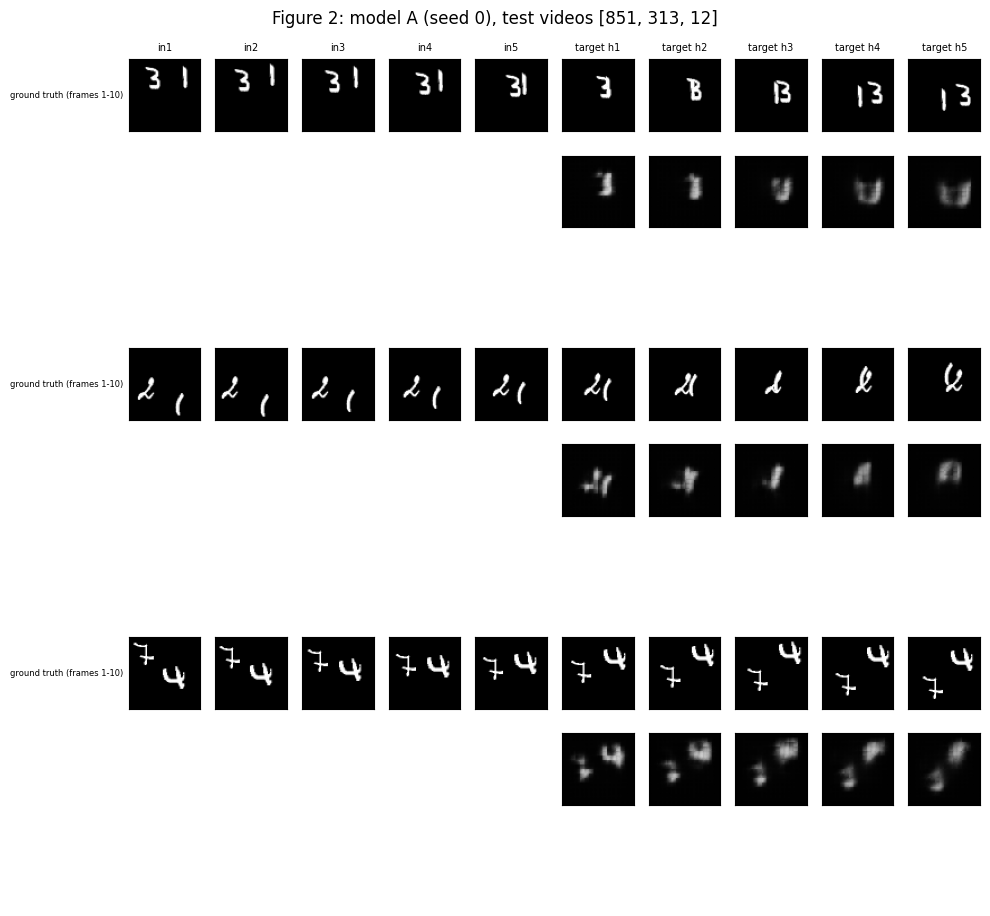

In [13]:
# ---- FIGURE 2: input, prediction, ground truth for three test videos (>=1 with overlapping digits)
# Overlap heuristic: digits are composited with max(), so overlapping reduces total ink. Eyeball the result!
def ink_drop(V, frames):                              # (N,) relative ink loss within the given 0-indexed frames
    ink = V[:, frames].sum(dim=(2, 3, 4)); return 1 - ink.min(1).values / ink.max(1).values
drop_future = ink_drop(TEST, list(range(5, 10)))      # frames 6-10 (the displayed targets)
FIG2_IDX = [int(i) for i in drop_future.argsort(descending=True)[:2]] + [int(drop_future.argmin())]   # 2 overlapping + 1 clean
# FIG2_IDX = [..., ..., ...]   # <- override with your own test-video indices after looking at the figure
print('Figure 2 test-video indices (0..999 within test split):', FIG2_IDX)

def fig_pred(f, idxs, title, path):
    fig, axs = plt.subplots(3 * len(idxs), 10, figsize=(10, 3.1 * len(idxs)))
    for n, i in enumerate(idxs):
        x, y = TEST[i, :5], TEST[i, 5:10]; P = run(f, x[None])[0]
        for c in range(10):
            for r, img in enumerate((TEST[i, c], None if c < 5 else P[c - 5, 0], None)):
                pass
        rows = [TEST[i, :10, 0], torch.cat([torch.full((5, 64, 64), float('nan')), P[:, 0]]), None]
        lab = ['ground truth (frames 1-10)', 'prediction (frames 6-10)']
        for r in range(2):
            for c in range(10):
                ax = axs[3 * n + r, c]; ax.set_xticks([]); ax.set_yticks([])
                im = rows[r][c]
                if not torch.isnan(im).any(): ax.imshow(im, cmap='gray', vmin=0, vmax=1)
                else: ax.axis('off')
                if c == 0 and ax.axison: ax.set_ylabel(lab[r], fontsize=6, rotation=0, ha='right', va='center')
                if n == 0 and r == 0: ax.set_title(f'in{c + 1}' if c < 5 else f'target h{c - 4}', fontsize=7)
        for c in range(10): axs[3 * n + 2, c].axis('off')
    fig.suptitle(title); plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()
fig_pred(MODELS[('A', 0)], FIG2_IDX, 'Figure 2: model A (seed 0), test videos ' + str(FIG2_IDX), 'figures/fig2.png')

**Report after running Section 3:** Table 2, Figure 2, **Q2.3** (should already be written), **Q2.4**.

---
# ⛔ GATE 1 – Q2.5 must be written and committed before Section 4
Write, **now**, your predictions: will model A pass the mirror test? the rotation test? At what speed will it break down, given your reach estimate (Q2.3) and Figure 1 (Q2.1)?
Paste your answer below and run the cell to commit it (the commit timestamp is your proof). Do **not** run anything in Section 4 first.

In [26]:
!git config --global user.email "ramsha4rasheed@gmail.com"
!git config --global user.name "ramsha4rasheed-png"

In [27]:
Q2_5 = """
The model A would not be able to pass the mirror test or the rotation test. Since the digit after the mirror transformation or rotation transformation are not exactly same as 2 and mirror 2 or 90degree rotated 2 do not look the same so as per figure 2 results. I do not believe that the model would be able to predict the digits correctly or move them correctly. The reach estimate is 8 and the median speed for breakdown in figure 1b is 3.32 so I think that the speed breakdown should be 3x for this particular example.
"""
commit_answer('Q2_5', Q2_5)      # commits answers/Q2_5.md ; add push=True once a remote is configured


On branch master
Untracked files:
  (use "git add <file>..." to include in what will be committed)
	.config/
	ckpt/
	data/
	figures/
	gifs/
	sample_data/
	tables/

nothing added to commit but untracked files present (use "git add" to track)


# Section 4 – Testing the baseline (Tables 3 & 4, Figures 3, 4, 5)
Run only after Gate 1.

**Report after running:** Table 3, Figure 3, Figure 4, Table 4, Figure 5, **Q2.6, Q2.7, Q2.8, Q2.9, Q2.10**.

In [14]:
# ---- TABLE 3: E(5), CM, EM, CR, ER
def table3(tags):
    rows = []
    for tag in tags:
        seeds = sorted(RES[tag]); d = {'Model': tag}
        for k, name in (('E5', 'E(5)'), ('CM', 'CM'), ('EM', 'EM'), ('CR', 'CR'), ('ER', 'ER')):
            d[name] = ms([RES[tag][s][k] for s in seeds])
        rows.append(d)
    return pd.DataFrame(rows)
T3 = table3(['A', 'Blank', 'Copy-last']); T3.to_csv('tables/table3.csv', index=False); display(T3)

,Model,E(5),CM,EM,CR,ER
0,A,"0.0219 (0.0224, 0.0214)","0.00193 (0.00185, 0.00202)","0.0226 (0.0231, 0.022)","0.00331 (0.00346, 0.00316)","0.0238 (0.0243, 0.0232)"
1,Blank,0.0426,0,0.0426,0,0.0426
2,Copy-last,0.0641,0,0.0641,0,0.0641


Top-2 per-video CM: [269, 621] [0.00743404 0.0055863 ] | Top-2 per-video CR: [733, 168] [0.00834204 0.00782353]


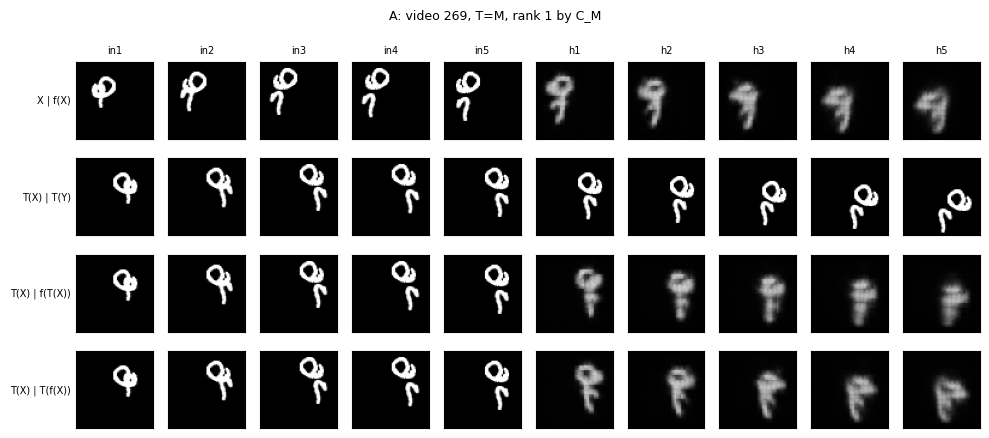

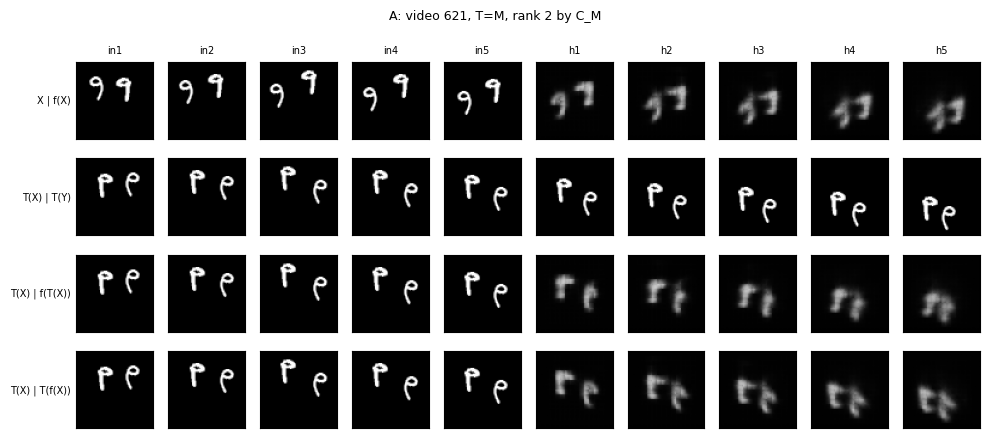

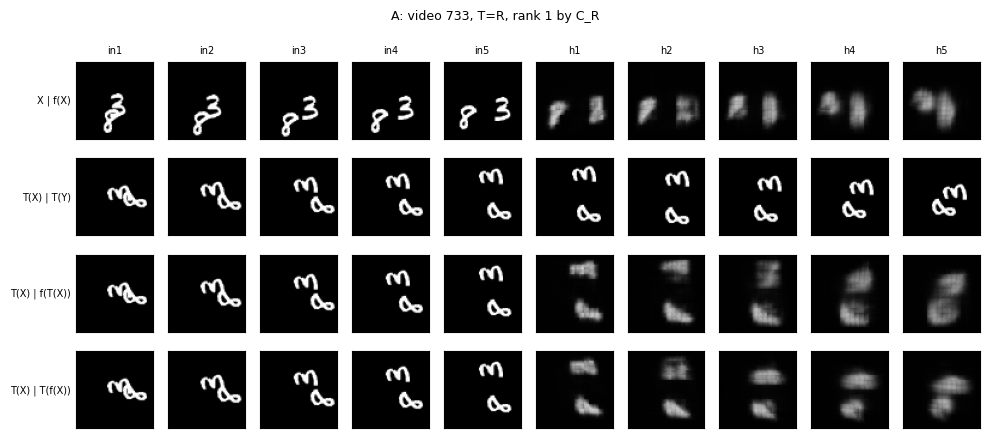

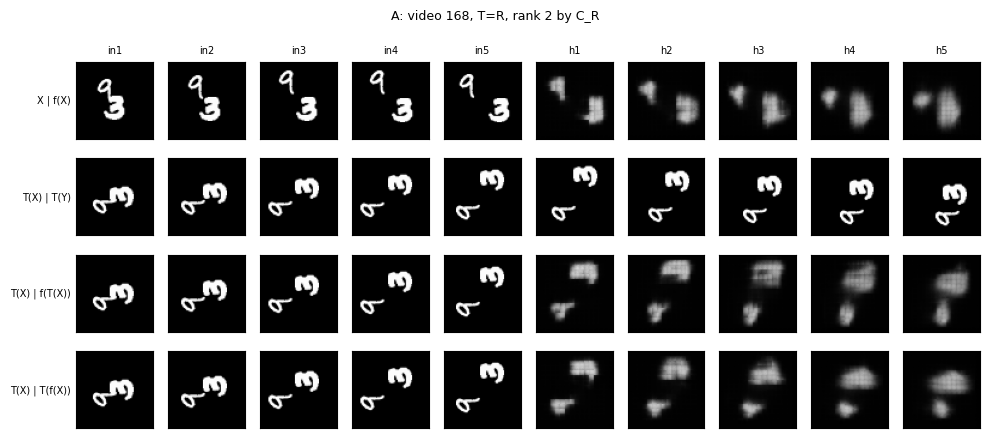

GIF paths for the caption:
   gifs/A_fig3_TM_rank1_video269.gif
   gifs/A_fig3_TM_rank2_video621.gif
   gifs/A_fig3_TR_rank1_video733.gif
   gifs/A_fig3_TR_rank2_video168.gif


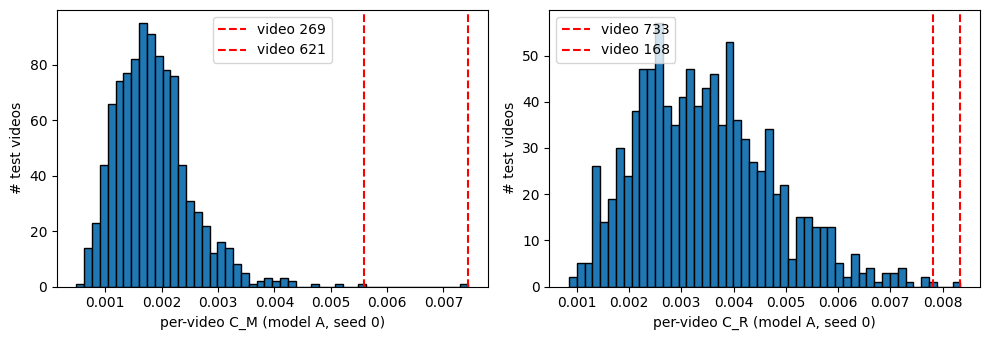

In [15]:
# ---- FIGURE 3 (+GIFs) and FIGURE 4, seed-0 model A
ROW_LABELS = ['X | f(X)', 'T(X) | T(Y)', 'T(X) | f(T(X))', 'T(X) | T(f(X))']

def panel_rows(f, i, T):
    x, y = TEST[i, :5], TEST[i, 5:10]
    fx = run(f, x[None])[0]; Tx, Ty = T(x), T(y); fTx = run(f, Tx[None])[0]; Tfx = T(fx)
    rows = [torch.cat([x, fx]), torch.cat([Tx, Ty]), torch.cat([Tx, fTx]), torch.cat([Tx, Tfx])]
    return [r[:, 0].numpy() for r in rows]

def draw_panel(rows, title, path):
    fig, axs = plt.subplots(4, 10, figsize=(10, 4.5))
    for r in range(4):
        for c in range(10):
            ax = axs[r, c]; ax.imshow(rows[r][c], cmap='gray', vmin=0, vmax=1); ax.set_xticks([]); ax.set_yticks([])
            if c == 0: ax.set_ylabel(ROW_LABELS[r], rotation=0, ha='right', va='center', fontsize=7)
            if r == 0: ax.set_title(f'in{c + 1}' if c < 5 else f'h{c - 4}', fontsize=7)
    fig.suptitle(title, fontsize=9); plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

def save_gif(rows, title, path):
    frames_ = []
    for h in range(5):                                   # one GIF frame per forecast horizon, same four rows
        fig, axs = plt.subplots(4, 2, figsize=(3.2, 5.2))
        for r in range(4):
            axs[r, 0].imshow(rows[r][h], cmap='gray', vmin=0, vmax=1); axs[r, 1].imshow(rows[r][5 + h], cmap='gray', vmin=0, vmax=1)
            axs[r, 0].set_ylabel(ROW_LABELS[r], rotation=0, ha='right', va='center', fontsize=6)
            for c in range(2): axs[r, c].set_xticks([]); axs[r, c].set_yticks([])
        axs[0, 0].set_title(f'input {h + 1}', fontsize=7); axs[0, 1].set_title(f'future h={h + 1}', fontsize=7)
        fig.suptitle(title, fontsize=7); fig.canvas.draw()
        frames_.append(np.asarray(fig.canvas.buffer_rgba())[..., :3].copy()); plt.close(fig)
    imageio.mimsave(path, frames_, fps=1, loop=0)

def per_video_C(f, T):
    X1 = TS[1][0]; return perC(run(f, T(X1)), T(run(f, X1))).numpy()

def make_fig3(f, sel, tag):
    paths = []
    for T_name, T, idxs in (('M', M, sel['M']), ('R', Rot, sel['R'])):
        for rank, i in enumerate(idxs):
            rows = panel_rows(f, i, T); title = f'{tag}: video {i}, T={T_name}, rank {rank + 1} by C_{T_name}'
            png = f'figures/{tag}_fig3_T{T_name}_rank{rank + 1}_video{i}.png'; gif = f'gifs/{tag}_fig3_T{T_name}_rank{rank + 1}_video{i}.gif'
            draw_panel(rows, title, png); save_gif(rows, title, gif); paths.append(gif)
    print('GIF paths for the caption:'); [print('  ', p) for p in paths]

fA = MODELS[('A', 0)]
CM_v, CR_v = per_video_C(fA, M), per_video_C(fA, Rot)
FIG3_SEL = {'M': [int(i) for i in np.argsort(-CM_v)[:2]], 'R': [int(i) for i in np.argsort(-CR_v)[:2]]}
print('Top-2 per-video CM:', FIG3_SEL['M'], CM_v[FIG3_SEL['M']], '| Top-2 per-video CR:', FIG3_SEL['R'], CR_v[FIG3_SEL['R']])
make_fig3(fA, FIG3_SEL, 'A')

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for a, v, name, sel in ((ax[0], CM_v, 'C_M', FIG3_SEL['M']), (ax[1], CR_v, 'C_R', FIG3_SEL['R'])):
    a.hist(v, bins=50, edgecolor='k')
    for j, i in enumerate(sel): a.axvline(v[i], color='r', ls='--', label=f'video {i}' if True else None)
    a.set_xlabel(f'per-video {name} (model A, seed 0)'); a.set_ylabel('# test videos'); a.legend()
plt.tight_layout(); plt.savefig('figures/fig4.png', dpi=150); plt.show()

In [16]:
# ---- TABLE 4: speed-up
def table4(tags):
    rows = []
    for tag in tags:
        seeds = sorted(RES[tag])
        rows.append({'Model': tag, **{n: ms([RES[tag][s][k] for s in seeds]) for k, n in
                     (('E2_1x', 'E(2) 1x'), ('E2_2x', 'E(2) 2x'), ('E2_3x', 'E(2) 3x'), ('E5', 'E(5) 1x'), ('E5_2x', 'E(5) 2x'))}})
    return pd.DataFrame(rows)
T4 = table4(['A', 'Copy-last']); T4.to_csv('tables/table4.csv', index=False); display(T4)

,Model,E(2) 1x,E(2) 2x,E(2) 3x,E(5) 1x,E(5) 2x
0,A,"0.0184 (0.019, 0.0178)","0.0453 (0.0446, 0.046)","0.0524 (0.0529, 0.0519)","0.0219 (0.0224, 0.0214)","0.0507 (0.0503, 0.051)"
1,Copy-last,0.0548,0.0661,0.0703,0.0641,0.0719


Figure 5 video: 85 | ink drop: 5.960464477539063e-08


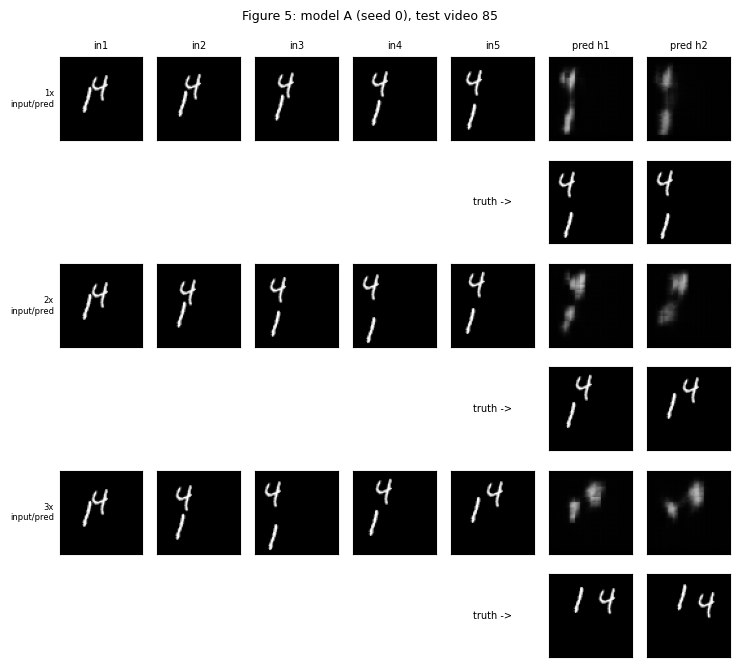

In [17]:
# ---- FIGURE 5: one non-overlapping test video at 1x, 2x, 3x (5 inputs + first two predicted and true targets)
drop_all = ink_drop(TEST, list(range(20)))        # heuristic: ~0 means no overlap anywhere in the video
FIG5_IDX = int(drop_all.argmin())
# FIG5_IDX = ...   # <- override after checking by eye that no displayed TRUE frame has overlapping digits
print('Figure 5 video:', FIG5_IDX, '| ink drop:', drop_all[FIG5_IDX].item())

def fig_speed(f, i, title, path):
    fig, axs = plt.subplots(6, 7, figsize=(7.5, 6.8))
    for r, k in enumerate((1, 2, 3)):
        xi, yi = window_idx(1, k); x = TEST[i, xi]; y = TEST[i, yi[:2]]; P = run(f, x[None])[0]
        for c in range(7):
            a1, a2 = axs[2 * r, c], axs[2 * r + 1, c]
            for a in (a1, a2): a.set_xticks([]); a.set_yticks([])
            if c < 5: a1.imshow(x[c, 0], cmap='gray', vmin=0, vmax=1); a2.axis('off')
            else: a1.imshow(P[c - 5, 0], cmap='gray', vmin=0, vmax=1); a2.imshow(y[c - 5, 0], cmap='gray', vmin=0, vmax=1)
            if c == 0: a1.set_ylabel(f'{k}x\ninput/pred', fontsize=6, rotation=0, ha='right', va='center')
            if r == 0 and 2 * r == 0: a1.set_title(f'in{c + 1}' if c < 5 else f'pred h{c - 4}', fontsize=7)
        axs[2 * r + 1, 5].set_ylabel('')
        axs[2 * r + 1, 4].text(0.5, 0.5, 'truth ->', ha='center', va='center', fontsize=7, transform=axs[2 * r + 1, 4].transAxes); axs[2 * r + 1, 4].axis('off')
    fig.suptitle(title, fontsize=9); plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()
fig_speed(fA, FIG5_IDX, f'Figure 5: model A (seed 0), test video {FIG5_IDX}', 'figures/fig5.png')

**Report after running Section 4:** Q2.6–Q2.10 (Q2.10: propose the experiment that separates "never seen fast motion" from "beyond reach" – Section 5 runs it).

---
# ⛔ GATE 2 – Q2.11 must be written and committed before Section 5
In at most three sentences, predict which of models B, C, D fixes which of the failures you found. Do **not** run any Section 5 cell (including the D candidate comparison) first.

In [ ]:
Q2_11 = """
PASTE YOUR Q2.11 PREDICTION HERE (max three sentences).
"""
commit_answer('Q2_11', Q2_11)

# Section 5 – What can data fix? Models B, C, D, Table 5
| Model | Architecture | Training speeds | Symmetry aug. |
|---|---|---|---|
| A | baseline | 1× | none |
| B | baseline | 1× | g ~ U(G) |
| C | baseline | k ~ U{1,2,3} | none |
| D | your design (reach > A, ≤ 721,176 params, no attention) | k ~ U{1,2,3} | none |

**Report after running:** Table 5, **Q2.12** (describe D + hand-calculate its reach exactly like Q2.3), **Q2.13**, **Q2.14**.

In [18]:
# ---- Model B (symmetry aug) and model C (speed aug), baseline architecture, seeds 0 and 1
for s in SEEDS:
    m, tt, _ = train_model('B', CFG_A, s, sym_aug=True);   register('B', s, m, tt)
    m, tt, _ = train_model('C', CFG_A, s, speed_aug=True); register('C', s, m, tt)

[B s0] ep  1/30 train 0.04608 | val E5 0.03932 | 12.7s
[B s0] ep  2/30 train 0.03967 | val E5 0.03854 | 12.9s
[B s0] ep  3/30 train 0.03869 | val E5 0.03733 | 12.5s
[B s0] ep  4/30 train 0.03723 | val E5 0.03561 | 12.3s
[B s0] ep  5/30 train 0.03534 | val E5 0.03391 | 12.3s
[B s0] ep  6/30 train 0.03378 | val E5 0.03387 | 12.4s
[B s0] ep  7/30 train 0.03226 | val E5 0.03116 | 12.6s
[B s0] ep  8/30 train 0.03135 | val E5 0.03068 | 12.7s
[B s0] ep  9/30 train 0.03065 | val E5 0.02979 | 12.6s
[B s0] ep 10/30 train 0.03005 | val E5 0.03047 | 12.4s
[B s0] ep 11/30 train 0.02950 | val E5 0.02926 | 12.4s
[B s0] ep 12/30 train 0.02914 | val E5 0.02866 | 12.5s
[B s0] ep 13/30 train 0.02875 | val E5 0.02820 | 12.5s
[B s0] ep 14/30 train 0.02825 | val E5 0.02885 | 12.5s
[B s0] ep 15/30 train 0.02791 | val E5 0.02747 | 12.5s
[B s0] ep 16/30 train 0.02747 | val E5 0.02720 | 12.5s
[B s0] ep 17/30 train 0.02712 | val E5 0.02686 | 12.5s
[B s0] ep 18/30 train 0.02678 | val E5 0.02648 | 12.5s
[B s0] ep 

In [19]:
# ---- Model D: candidate designs, compared on the VALIDATION split only (seed 0, full protocol, speed aug).
# Constraints: params <= 721,176 ; one-step reach strictly larger than model A's (8 px) ; no attention ; same I/O + rollout.
CANDS = {
  'D_dil22': dict(patch=4, hid=64, ks=(3, 3), dil=(2, 2)),    # dilated 3x3 in both layers (same params as A)
  'D_dil33': dict(patch=4, hid=64, ks=(3, 3), dil=(3, 3)),    # more dilation, sparser sampling
  'D_p8':    dict(patch=8, hid=64, ks=(3, 3), dil=(1, 1)),    # bigger patch: 8x8 folded grid, one cell = 8 px
}
REACH_A = reach_px(4, (3, 3), (1, 1))
for n, c in CANDS.items():
    P_ = n_params(ConvRNN(**c)); Rr = reach_px(c['patch'], c['ks'], c['dil'])
    assert P_ <= PARAM_LIMIT_D and Rr > REACH_A, (n, P_, Rr)
    print(f'{n}: params {P_:,} (limit {PARAM_LIMIT_D:,}), helper reach {Rr} px (A: {REACH_A})')

CAND_VAL = {}
for n, c in CANDS.items():
    m, tt, _ = train_model(n, c, 0, speed_aug=True)
    CAND_VAL[n] = val_score(m); print(n, 'VAL E(2) at 1x/2x/3x:', {k: round(v, 5) for k, v in CAND_VAL[n].items()})
D_NAME = min(CAND_VAL, key=lambda n: np.mean(list(CAND_VAL[n].values())))   # criterion: mean val E(2) over 1x,2x,3x
# D_NAME = 'D_dil22'   # <- override if you prefer another criterion (validation only!)
CFG_D = CANDS[D_NAME]; print('Chosen model D:', D_NAME, CFG_D)
pd.DataFrame(CAND_VAL).T.rename(columns={1: 'val E2 1x', 2: 'val E2 2x', 3: 'val E2 3x'}).to_csv('tables/D_candidates_val.csv'); display(pd.DataFrame(CAND_VAL).T)

D_dil22: params 480,784 (limit 721,176), helper reach 16 px (A: 8)
D_dil33: params 480,784 (limit 721,176), helper reach 24 px (A: 8)
D_p8: params 594,496 (limit 721,176), helper reach 16 px (A: 8)
[D_dil22 s0] ep  1/30 train 0.04648 | val E5 0.03916 | 20.9s
[D_dil22 s0] ep  2/30 train 0.03972 | val E5 0.03887 | 21.3s
[D_dil22 s0] ep  3/30 train 0.03935 | val E5 0.03831 | 20.3s
[D_dil22 s0] ep  4/30 train 0.03855 | val E5 0.03734 | 20.3s
[D_dil22 s0] ep  5/30 train 0.03791 | val E5 0.03669 | 20.8s
[D_dil22 s0] ep  6/30 train 0.03723 | val E5 0.03610 | 20.8s
[D_dil22 s0] ep  7/30 train 0.03673 | val E5 0.03534 | 20.5s
[D_dil22 s0] ep  8/30 train 0.03627 | val E5 0.03473 | 20.6s
[D_dil22 s0] ep  9/30 train 0.03583 | val E5 0.03492 | 20.7s
[D_dil22 s0] ep 10/30 train 0.03541 | val E5 0.03385 | 20.8s
[D_dil22 s0] ep 11/30 train 0.03488 | val E5 0.03350 | 20.8s
[D_dil22 s0] ep 12/30 train 0.03431 | val E5 0.03280 | 20.8s
[D_dil22 s0] ep 13/30 train 0.03373 | val E5 0.03177 | 20.8s
[D_dil22 

,1,2,3
D_dil22,0.025781,0.028785,0.030505
D_dil33,0.037362,0.037357,0.037378
D_p8,0.027495,0.029192,0.030970


In [20]:
# ---- Train model D (speed aug), seeds 0 and 1.  Seed-0 run is identical to the candidate run, so reuse it if epochs match.
for s in SEEDS:
    src, dst = f'ckpt/{D_NAME}_seed{s}_ep{EPOCHS}.pt', f'ckpt/D_seed{s}_ep{EPOCHS}.pt'
    if os.path.exists(src) and not os.path.exists(dst): shutil.copy(src, dst)
    m, tt, _ = train_model('D', CFG_D, s, speed_aug=True); register('D', s, m, tt)
print('Model D reach (helper check):', reach_px(CFG_D['patch'], CFG_D['ks'], CFG_D['dil']), 'px | params:', n_params(MODELS[('D', 0)]))

[D seed 0] loaded ckpt/D_seed0_ep30.pt
D seed 0: E5=0.02841  CM=0.0009477 EM=0.02877 CR=0.001781 ER=0.02957
[D s1] ep  1/30 train 0.04844 | val E5 0.03948 | 20.7s
[D s1] ep  2/30 train 0.04019 | val E5 0.03947 | 20.5s
[D s1] ep  3/30 train 0.04019 | val E5 0.03947 | 20.3s
[D s1] ep  4/30 train 0.04008 | val E5 0.03924 | 20.4s
[D s1] ep  5/30 train 0.03979 | val E5 0.03888 | 20.4s
[D s1] ep  6/30 train 0.03940 | val E5 0.03848 | 20.4s
[D s1] ep  7/30 train 0.03870 | val E5 0.03727 | 20.4s
[D s1] ep  8/30 train 0.03772 | val E5 0.03652 | 20.5s
[D s1] ep  9/30 train 0.03689 | val E5 0.03541 | 20.6s
[D s1] ep 10/30 train 0.03621 | val E5 0.03451 | 20.6s
[D s1] ep 11/30 train 0.03561 | val E5 0.03375 | 20.6s
[D s1] ep 12/30 train 0.03488 | val E5 0.03317 | 20.6s
[D s1] ep 13/30 train 0.03421 | val E5 0.03192 | 20.7s
[D s1] ep 14/30 train 0.03371 | val E5 0.03175 | 20.7s
[D s1] ep 15/30 train 0.03325 | val E5 0.03111 | 20.7s
[D s1] ep 16/30 train 0.03281 | val E5 0.03094 | 20.7s
[D s1] ep 17

In [21]:
# ---- TABLE 5
KEYS5 = [('E5', 'E(5) 1x'), ('CM', 'CM'), ('EM', 'EM'), ('CR', 'CR'), ('ER', 'ER'),
         ('E2_1x', 'E(2) 1x'), ('E2_2x', 'E(2) 2x'), ('E2_3x', 'E(2) 3x'),
         ('params', 'Params'), ('train_time', 'Train s/epoch'), ('infer_time', 'Inference s (1000 vids)')]
def table_models(tags, rename=None):
    rows = []
    for tag in tags:
        seeds = sorted(RES[tag]); d = {'Model': (rename or {}).get(tag, tag)}
        for k, n in KEYS5:
            d[n] = fmt(RES[tag][seeds[0]][k]) if k == 'params' else ms([RES[tag][s][k] for s in seeds])
        rows.append(d)
    return pd.DataFrame(rows)
T5 = table_models(['A', 'B', 'C', 'D']); T5.to_csv('tables/table5.csv', index=False); display(T5)
print('Hardware for timings:', HARDWARE)

,Model,E(5) 1x,CM,EM,CR,ER,E(2) 1x,E(2) 2x,E(2) 3x,Params,Train s/epoch,Inference s (1000 vids)
0,A,"0.0219 (0.0224, 0.0214)","0.00193 (0.00185, 0.00202)","0.0226 (0.0231, 0.022)","0.00331 (0.00346, 0.00316)","0.0238 (0.0243, 0.0232)","0.0184 (0.019, 0.0178)","0.0453 (0.0446, 0.046)","0.0524 (0.0529, 0.0519)","480,784","12 (12, 12.1)","0.439 (0.442, 0.435)"
1,B,"0.0229 (0.0236, 0.0223)","0.00117 (0.00113, 0.0012)","0.0229 (0.0236, 0.0223)","0.00159 (0.00144, 0.00174)","0.0229 (0.0236, 0.0222)","0.019 (0.0196, 0.0185)","0.0454 (0.0441, 0.0467)","0.0521 (0.0506, 0.0535)","480,784","12.5 (12.5, 12.5)","0.441 (0.438, 0.444)"
2,C,"0.0269 (0.0274, 0.0264)","0.00128 (9.66e-04, 0.0016)","0.0272 (0.0277, 0.0267)","0.00273 (0.00227, 0.00318)","0.0282 (0.0286, 0.0277)","0.0231 (0.0233, 0.0229)","0.0288 (0.0292, 0.0284)","0.0337 (0.0338, 0.0336)","480,784","12.1 (12.2, 12.1)","0.438 (0.436, 0.44)"
3,D,"0.0283 (0.0284, 0.0282)","0.00104 (9.48e-04, 0.00114)","0.0287 (0.0288, 0.0285)","0.00194 (0.00178, 0.0021)","0.0294 (0.0296, 0.0293)","0.0259 (0.026, 0.0258)","0.0289 (0.0288, 0.0289)","0.0312 (0.031, 0.0315)","480,784","20.7 (20.7, 20.6)","0.87 (0.872, 0.869)"


Hardware for timings: Tesla T4


**Report after running Section 5:** Table 5, **Q2.12–Q2.14**.

# Section 6 – The final model: symmetrised forecaster
$\bar f(X) = \frac18\sum_{g\in G} g^{-1}\big(f(g(X))\big)$. **Report:** a short argument that $\bar f$ has $C_M=C_R=0$ exactly for any $f$ (hint: $\bar f(hX)$ for $h\in G$ re-indexes the sum because $G$ is a group), Table 6, Figure 6, **Q2.15, Q2.16, Q2.17**.

In [22]:
def sym_forecaster(model):
    model.eval()
    def f(X):
        out = 0
        for g in G: out = out + inv_g(model(apply_g(X, g)), g)
        return out / 8
    return f

# ---- Optional: D+B (speed AND symmetry augmentation). Enable only if Table 5 supports it.
TRAIN_DB = False
if TRAIN_DB:
    for s in SEEDS:
        m, tt, _ = train_model('D+B', CFG_D, s, speed_aug=True, sym_aug=True); register('D+B', s, m, tt)

for base in ['B', 'D'] + (['D+B'] if TRAIN_DB else []):
    for s in SEEDS:
        fs = sym_forecaster(MODELS[(base, s)])
        r = metrics(fs); r['params'] = RES[base][s]['params']
        r['train_time'] = RES[base][s]['train_time']                 # symmetrisation needs no training
        r['infer_time'] = time_inference(fs, TS[1][0])               # includes 8 transforms, passes, inverses, averaging
        RES.setdefault('sym-' + base, {})[s] = r
        print(f'sym-{base} seed {s}: CM={r["CM"]:.2e} CR={r["CR"]:.2e} E5={r["E5"]:.4g} ER={r["ER"]:.4g} E2_3x={r["E2_3x"]:.4g}')

sym-B seed 0: CM=7.75e-17 CR=6.24e-17 E5=0.02296 ER=0.02296 E2_3x=0.04988
sym-B seed 1: CM=9.62e-17 CR=7.73e-17 E5=0.02154 ER=0.02154 E2_3x=0.05247
sym-D seed 0: CM=4.54e-17 CR=3.56e-17 E5=0.02842 ER=0.02842 E2_3x=0.03065
sym-D seed 1: CM=6.23e-17 CR=4.89e-17 E5=0.02809 ER=0.02809 E2_3x=0.03125


In [23]:
# ---- TABLE 6  (CM, CR printed in scientific notation by fmt)
FINAL = 'D'      # 'D' or 'D+B' (needs TRAIN_DB=True). State and justify your choice using Table 5.
tags6 = ['sym-B', 'sym-D'] + (['sym-D+B'] if TRAIN_DB else [])
T6 = table_models(tags6); T6.to_csv('tables/table6.csv', index=False); display(T6)
print('Final model = symmetrised', FINAL)

,Model,E(5) 1x,CM,EM,CR,ER,E(2) 1x,E(2) 2x,E(2) 3x,Params,Train s/epoch,Inference s (1000 vids)
0,sym-B,"0.0222 (0.023, 0.0215)","8.68e-17 (7.75e-17, 9.62e-17)","0.0222 (0.023, 0.0215)","6.98e-17 (6.24e-17, 7.73e-17)","0.0222 (0.023, 0.0215)","0.0186 (0.0192, 0.018)","0.0447 (0.0435, 0.046)","0.0512 (0.0499, 0.0525)","480,784","12.5 (12.5, 12.5)","3.77 (3.74, 3.8)"
1,sym-D,"0.0283 (0.0284, 0.0281)","5.38e-17 (4.54e-17, 6.23e-17)","0.0283 (0.0284, 0.0281)","4.22e-17 (3.56e-17, 4.89e-17)","0.0283 (0.0284, 0.0281)","0.026 (0.0261, 0.0259)","0.0288 (0.0288, 0.0289)","0.0309 (0.0307, 0.0312)","480,784","20.7 (20.7, 20.6)","7 (7, 7.01)"


Final model = symmetrised D


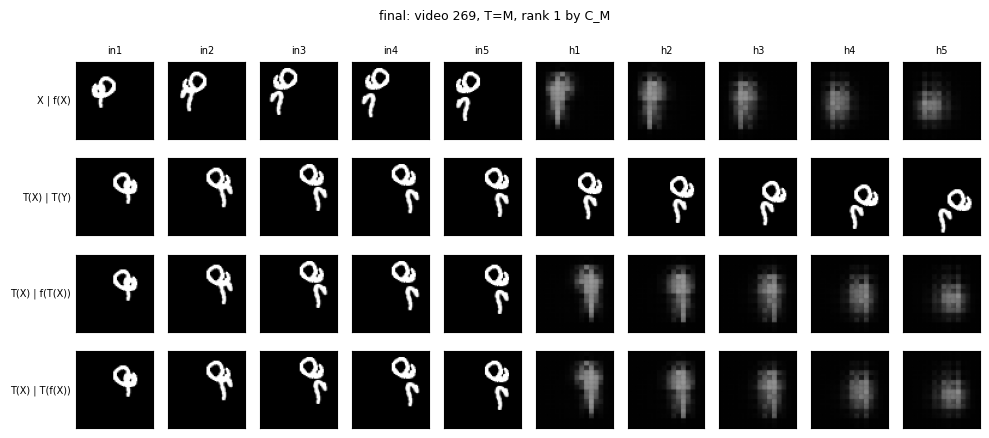

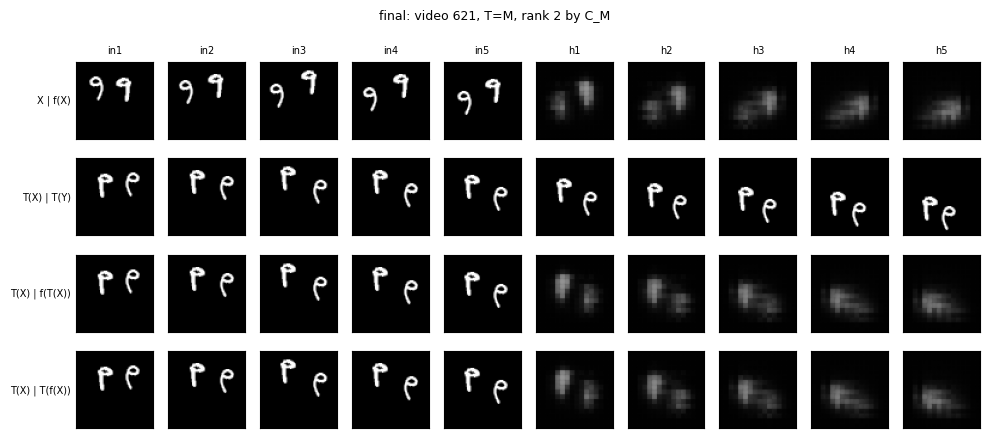

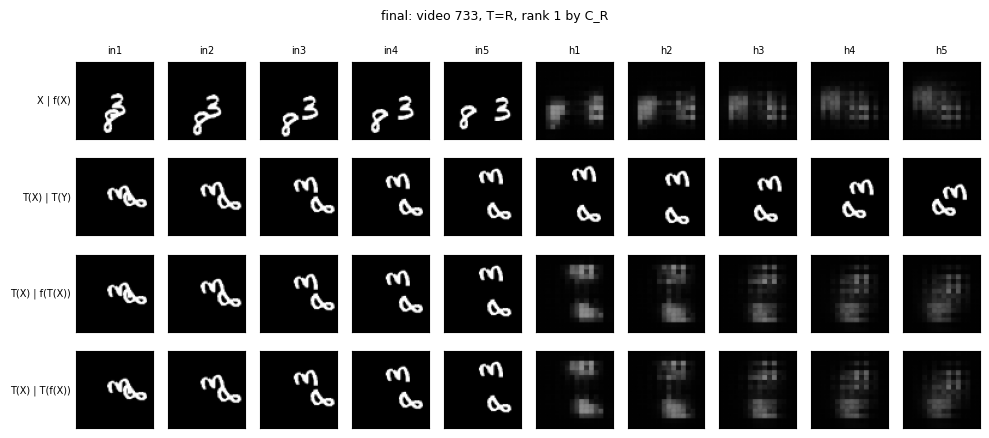

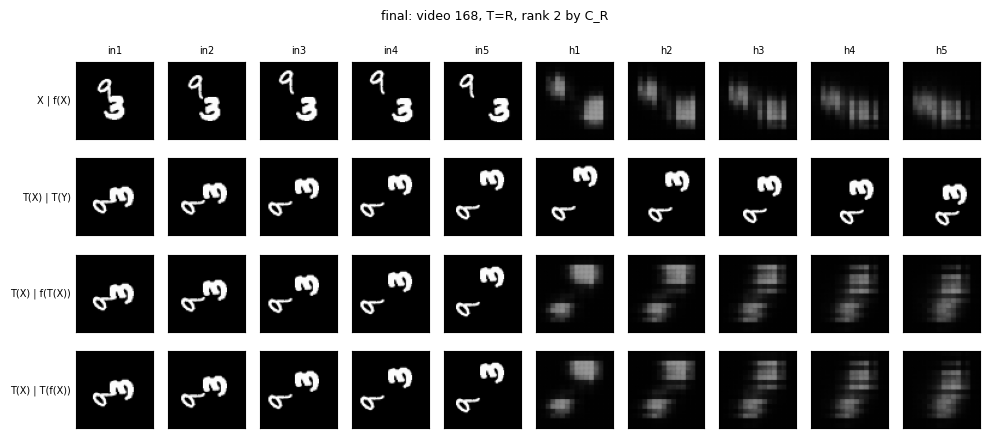

GIF paths for the caption:
   gifs/final_fig3_TM_rank1_video269.gif
   gifs/final_fig3_TM_rank2_video621.gif
   gifs/final_fig3_TR_rank1_video733.gif
   gifs/final_fig3_TR_rank2_video168.gif


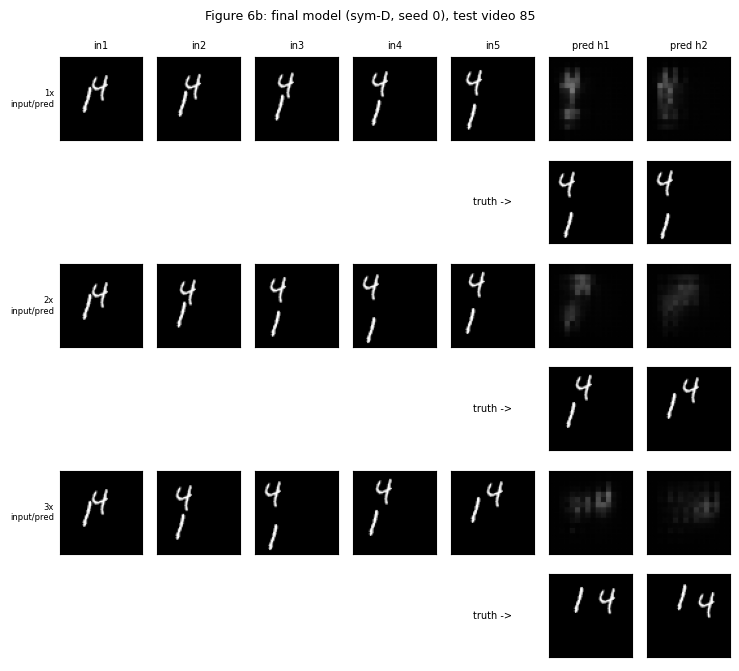

In [24]:
# ---- FIGURE 6 (a): Figure 3 videos with the final model (same videos);  (b): Figure 5 video with the final model
f_final = sym_forecaster(MODELS[(FINAL, 0)])
make_fig3(f_final, FIG3_SEL, 'final')                                   # GIFs saved under gifs/final_fig3_*
fig_speed(f_final, FIG5_IDX, f'Figure 6b: final model (sym-{FINAL}, seed 0), test video {FIG5_IDX}', 'figures/fig6b.png')

**Report after running Section 6:** Table 6, Figure 6 (a: `figures/final_fig3_*.png` + GIF paths; b: `figures/fig6b.png`), the exactness argument, **Q2.15, Q2.16** (compare with the video you chose in Q2.7), **Q2.17** (≤150 words).

# Section 7 – Save everything

In [25]:
def jsonable(o):
    if isinstance(o, dict): return {str(k): jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [jsonable(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    return o
json.dump(jsonable({'hardware': HARDWARE, 'epochs': EPOCHS, 'results': RES,
                    'fig2': FIG2_IDX, 'fig3': FIG3_SEL, 'fig5': FIG5_IDX, 'D_name': D_NAME, 'D_cfg': CFG_D}),
          open('tables/all_results.json', 'w'), indent=1)
assert not QUICK_TEST, 'QUICK_TEST was on - rerun with QUICK_TEST=False for reportable numbers'
print('Saved tables/, figures/, gifs/, ckpt/. Commit them to your public repo, with answers/Q2_5.md and answers/Q2_11.md.')

Saved tables/, figures/, gifs/, ckpt/. Commit them to your public repo, with answers/Q2_5.md and answers/Q2_11.md.
